In [25]:
DEBUG = False                        # quick test first; then False for the full run
NUM_FRAMES, IMG = 16, 224
BATCH, ACCUM = 8, 4                 # effective batch 32, as in the paper
EPOCHS = 2 if DEBUG else 30
PATIENCE = 10                       # early stopping on val loss (paper)
LR_BACKBONE, LR_HEAD, WD = 1e-4, 1e-3, 1e-4   # (D) lower LR for the pretrained CNN
TIME_LIMIT_H = 10.5                 # stop safely before Kaggle's 12 h limit
INIT_HEAD = False                    # start GRU/attention/classifier from Stage 1 weights

In [17]:
import os, glob, shutil, subprocess, json, time, random, copy
import numpy as np, pandas as pd

rar_files = sorted(glob.glob('/kaggle/input/**/*.rar', recursive=True))
assert rar_files, 'Add Input: 01-download-cricshot10k'
if shutil.which('unrar') is None and shutil.which('7z') is None:
    subprocess.run('apt-get -qq update && apt-get -qq install -y unrar p7zip-full', shell=True)
ROOT = '/tmp/videos'; os.makedirs(ROOT, exist_ok=True)
for r in rar_files:
    cmd = (['unrar', 'x', '-o+', '-idq', r, ROOT + '/'] if shutil.which('unrar')
           else ['7z', 'x', '-y', '-bso0', '-bsp0', r, f'-o{ROOT}'])
    subprocess.run(cmd, check=True)

IN04 = os.path.dirname(glob.glob('/kaggle/input/**/crop_boxes.npy', recursive=True)[0])
meta  = pd.read_csv(f'{IN04}/metadata.csv')
boxes = np.load(f'{IN04}/crop_boxes.npy').astype(int)
classes = meta.drop_duplicates('label').sort_values('label')['class'].tolist(); C = len(classes)

split_ids = {s: np.where(meta['split_match'] == s)[0] for s in ['train', 'val', 'test']}
if DEBUG:
    rng = np.random.default_rng(0)
    split_ids = {s: rng.choice(v, n, replace=False) for (s, v), n in zip(split_ids.items(), [256, 96, 96])}
use = np.concatenate(list(split_ids.values()))
row_of = {orig: k for k, orig in enumerate(use)}          # original clip index -> row in frame cache
print({s: len(v) for s, v in split_ids.items()}, '| classes:', C)

{'train': 256, 'val': 96, 'test': 96} | classes: 15


In [18]:
import cv2, torch
from torch.utils.data import Dataset, DataLoader
from numpy.lib.format import open_memmap
from tqdm.auto import tqdm
cv2.setNumThreads(0)

class CropFromBoxes(Dataset):
    def __init__(self, orig_ids): self.ids = orig_ids
    def __len__(self): return len(self.ids)
    def __getitem__(self, k):
        i = self.ids[k]
        cap = cv2.VideoCapture(os.path.join(ROOT, meta.path[i])); frames = []
        while True:
            ok, f = cap.read()
            if not ok: break
            frames.append(f)
        cap.release()
        idx = np.linspace(0, len(frames) - 1, NUM_FRAMES).round().astype(int)
        crops = [cv2.cvtColor(cv2.resize(frames[j][y1:y2, x1:x2], (IMG, IMG), interpolation=cv2.INTER_AREA),
                              cv2.COLOR_BGR2RGB) for j, (x1, y1, x2, y2) in zip(idx, boxes[i])]
        return torch.from_numpy(np.stack(crops)), k

CACHE = '/tmp/frames_u8.npy'
cache = open_memmap(CACHE, mode='w+', dtype=np.uint8, shape=(len(use), NUM_FRAMES, IMG, IMG, 3))
t0 = time.time()
for clips, ks in tqdm(DataLoader(CropFromBoxes(use), batch_size=16, num_workers=4)):
    cache[ks.numpy()] = clips.numpy()
cache.flush(); del cache
frames = np.load(CACHE, mmap_mode='r')
print(f'Cache {frames.shape} built in {(time.time() - t0) / 60:.1f} min')

  0%|          | 0/28 [00:00<?, ?it/s]

Cache (448, 16, 224, 224, 3) built in 0.4 min


In [23]:
import torchvision.transforms.functional as TF
device = 'cuda'

class CachedClips(Dataset):
    def __init__(self, orig_ids):
        self.rows = [row_of[i] for i in orig_ids]
        self.labels = meta['label'].values[orig_ids]
    def __len__(self): return len(self.rows)
    def __getitem__(self, k):
        return torch.from_numpy(np.array(frames[self.rows[k]])), int(self.labels[k])

def make_loader(split, shuffle):
    return DataLoader(CachedClips(split_ids[split]), batch_size=BATCH, shuffle=shuffle,
                      num_workers=4, pin_memory=True, drop_last=shuffle, persistent_workers=True)
train_loader, val_loader, test_loader = make_loader('train', True), make_loader('val', False), make_loader('test', False)

MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 1, 3, 1, 1)

def augment_clip(clip):
    """SAME random transform for all frames of a clip (their code applied it per frame)."""
    if random.random() < 0.5:
        clip = TF.hflip(clip)
    clip = TF.rotate(clip, random.uniform(-10, 10))
    clip = TF.adjust_brightness(clip, random.uniform(0.8, 1.2))
    clip = TF.adjust_contrast(clip, random.uniform(0.8, 1.2))
    clip = TF.adjust_saturation(clip, random.uniform(0.8, 1.2))
    clip = TF.adjust_hue(clip, random.uniform(-0.1, 0.1))
    return clip.clamp(0, 1)

def to_input(u8, train):
    x = u8.to(device, non_blocking=True).permute(0, 1, 4, 2, 3).float() / 255.   # (B, T, 3, H, W)
    if train:
        x = torch.stack([augment_clip(c) for c in x])
    return (x - MEAN) / STD

In [26]:
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

class SpatialAttention(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.att = nn.Sequential(nn.Linear(d, d // 8), nn.ReLU(), nn.Linear(d // 8, d), nn.Sigmoid())
    def forward(self, x): return x * self.att(x)

class TemporalAttentionPaper(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.score = nn.Sequential(nn.Linear(d, d // 4), nn.ReLU(), nn.Linear(d // 4, 1))
    def forward(self, H):
        a = torch.softmax(self.score(H).squeeze(-1), dim=1)
        return (a.unsqueeze(-1) * H).sum(1), a

class PaperModel(nn.Module):        # identical to Notebook 05, so Stage 1 weights load directly
    def __init__(self, num_classes, in_dim=1280, hidden=256):
        super().__init__()
        self.se = SpatialAttention(in_dim)
        self.rnn = nn.GRU(in_dim, hidden, num_layers=2, batch_first=True, dropout=0.2, bidirectional=True)
        self.attn = TemporalAttentionPaper(2 * hidden)
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(2 * hidden, 512), nn.ReLU(),
                                  nn.Dropout(0.2), nn.Linear(512, num_classes))
    def forward(self, x):
        z, a = self.attn(self.rnn(self.se(x))[0])
        return self.head(z), a

class FullModel(nn.Module):
    """EfficientNet-B0 (trainable) applied to every frame -> PaperModel head."""
    def __init__(self, num_classes):
        super().__init__()
        b0 = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
        self.backbone = nn.Sequential(b0.features, b0.avgpool, nn.Flatten())   # 1280 per frame
        self.temporal = PaperModel(num_classes)
    def forward(self, x):                                   # x: (B, T, 3, H, W)
        B, T = x.shape[:2]
        f = self.backbone(x.flatten(0, 1)).view(B, T, -1)
        return self.temporal(f)

model = FullModel(C).to(device)
if INIT_HEAD:
    head_ckpt = glob.glob('/kaggle/input/**/paper_head_frozen.pt', recursive=True)
    assert head_ckpt, 'Add Input: 05-paper-architecture-frozen (or set INIT_HEAD = False)'
    model.temporal.load_state_dict(torch.load(head_ckpt[0], map_location=device)['state_dict'])
    print('Loaded Stage 1 head weights ✅')
print(f'Total params: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M')

Total params: 8.30M


In [27]:
from sklearn.metrics import f1_score

counts = np.bincount(meta['label'].values[split_ids['train']], minlength=C).astype(np.float32)
crit = nn.CrossEntropyLoss(weight=torch.tensor(counts.sum() / (C * counts), device=device),
                           label_smoothing=0.1)

opt = torch.optim.AdamW([
    {'params': model.backbone.parameters(), 'lr': LR_BACKBONE},     # (D) gentle on pretrained CNN
    {'params': model.temporal.parameters(), 'lr': LR_HEAD},
], weight_decay=WD)
sched  = torch.optim.lr_scheduler.StepLR(opt, step_size=10, gamma=0.5)
scaler = torch.amp.GradScaler('cuda')

@torch.no_grad()
def evaluate(loader):
    model.eval(); logits, labels = [], []
    for xb, yb in loader:
        with torch.autocast('cuda', dtype=torch.float16):
            logits.append(model(to_input(xb, False))[0].float())
        labels.append(yb.to(device))
    logits, labels = torch.cat(logits), torch.cat(labels); pred = logits.argmax(1)
    return {'loss': crit(logits, labels).item(), 'acc': (pred == labels).float().mean().item(),
            'top3': (logits.topk(3, 1).indices == labels[:, None]).any(1).float().mean().item(),
            'macro_f1': f1_score(labels.cpu(), pred.cpu(), average='macro'),
            'logits': logits.cpu(), 'labels': labels.cpu()}

# Resume support: attach a previous version's output containing ckpt_last.pt to continue training
start_ep, best_acc, best_vloss, bad, history = 1, -1, float('inf'), 0, []
prev = glob.glob('/kaggle/input/**/ckpt_last.pt', recursive=True)
if prev and not DEBUG:
    ck = torch.load(prev[0], map_location=device)
    model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt'])
    sched.load_state_dict(ck['sched']); scaler.load_state_dict(ck['scaler'])
    start_ep, best_acc, best_vloss, bad, history = ck['epoch'] + 1, ck['best_acc'], ck['best_vloss'], ck['bad'], ck['history']
    print('Resumed from epoch', ck['epoch'])

OUT = '/kaggle/working'; t_start = time.time()
for ep in range(start_ep, EPOCHS + 1):
    model.train(); opt.zero_grad(set_to_none=True); t0 = time.time(); run_loss = 0
    for step, (xb, yb) in enumerate(tqdm(train_loader, desc=f'epoch {ep}', leave=False)):
        with torch.autocast('cuda', dtype=torch.float16):
            loss = crit(model(to_input(xb, True))[0], yb.to(device)) / ACCUM
        scaler.scale(loss).backward(); run_loss += loss.item() * ACCUM
        if (step + 1) % ACCUM == 0 or step + 1 == len(train_loader):
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
    sched.step()
    val = evaluate(val_loader)
    history.append({'epoch': ep, 'train_loss': run_loss / len(train_loader), 'val_loss': val['loss'],
                    'val_acc': val['acc'], 'val_f1': val['macro_f1'], 'min': (time.time() - t0) / 60})
    print(f"ep {ep:2d} | train loss {history[-1]['train_loss']:.3f} | val loss {val['loss']:.3f} "
          f"acc {val['acc']:.3f} f1 {val['macro_f1']:.3f} | {history[-1]['min']:.1f} min")

    if val['acc'] > best_acc:                      # keep best val accuracy (paper)
        best_acc = val['acc']; torch.save(model.state_dict(), f'{OUT}/best_finetuned.pt')
    if val['loss'] < best_vloss: best_vloss, bad = val['loss'], 0   # early stop on val loss (paper)
    else: bad += 1
    torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(),
                'scaler': scaler.state_dict(), 'epoch': ep, 'best_acc': best_acc, 'best_vloss': best_vloss,
                'bad': bad, 'history': history}, f'{OUT}/ckpt_last.pt')
    pd.DataFrame(history).to_csv(f'{OUT}/history.csv', index=False)

    if bad >= PATIENCE:
        print('Early stopping'); break
    if (time.time() - t_start) / 3600 > TIME_LIMIT_H:
        print('Time limit reached - attach this output and re-run to resume'); break

per_clip = np.mean([h['min'] for h in history]) / len(train_loader.dataset)
print(f"Estimated full-data epoch: {per_clip * 7254:.1f} min")

epoch 1:   0%|          | 0/32 [00:00<?, ?it/s]

ep  1 | train loss 2.891 | val loss 2.817 acc 0.094 f1 0.044 | 0.5 min


epoch 2:   0%|          | 0/32 [00:00<?, ?it/s]

ep  2 | train loss 2.849 | val loss 2.792 acc 0.146 f1 0.073 | 0.2 min
Estimated full-data epoch: 9.4 min


TEST  acc 0.1250 | top-3 0.4167 | macro F1 0.0691
                 precision    recall  f1-score   support

    Cover Drive      0.000     0.000     0.000         6
      Defensive      0.222     0.333     0.267         6
Down The Wicket      0.146     1.000     0.255         6
          Flick      0.000     0.000     0.000         8
           Hook      0.500     0.125     0.200         8
       Late Cut      0.000     0.000     0.000         4
 Lofted Legside      0.000     0.000     0.000        11
 Lofted Offside      0.250     0.143     0.182        14
           Pull      0.000     0.000     0.000         6
  Reverse Sweep      0.000     0.000     0.000         1
          Scoop      0.000     0.000     0.000         1
     Square Cut      0.000     0.000     0.000         9
 Straight Drive      0.091     0.250     0.133         4
          Sweep      0.000     0.000     0.000        11
      Upper Cut      0.000     0.000     0.000         1

       accuracy                     

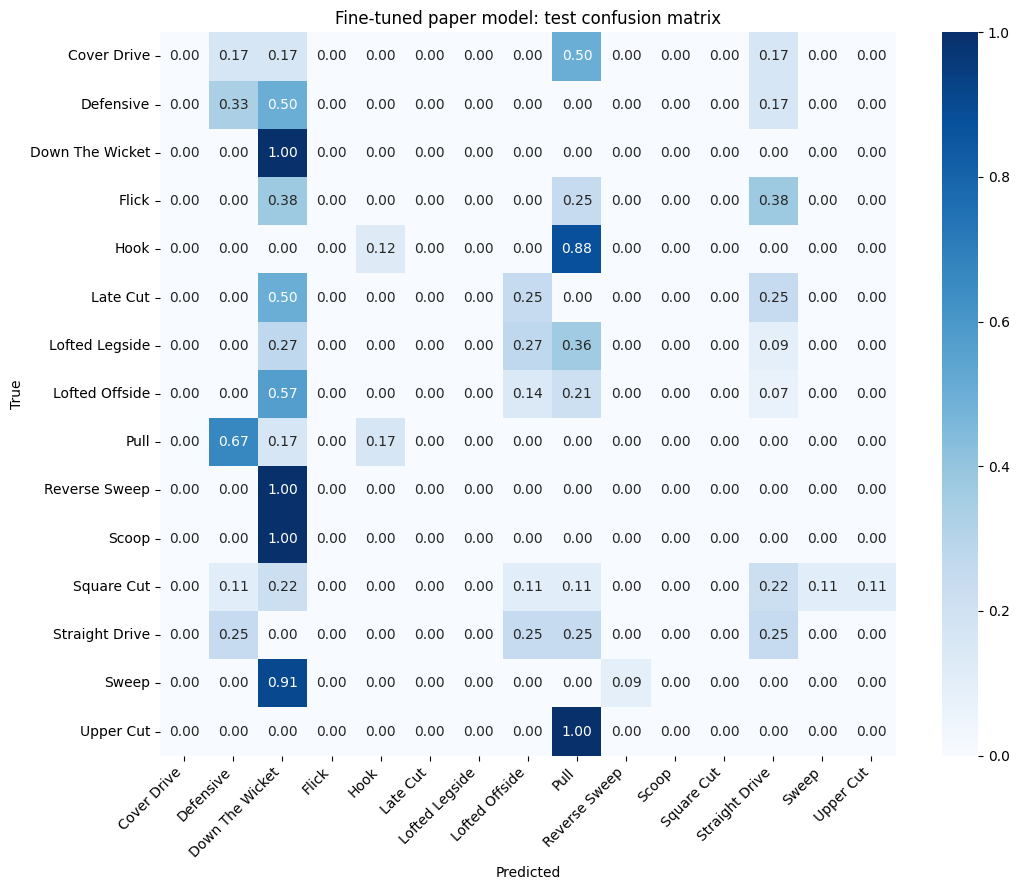

                                  setup  test_acc
0      Frozen B0 + paper head (Stage 1)     0.722
1  Fine-tuned B0 + paper head (Stage 2)     0.125


In [28]:
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

model.load_state_dict(torch.load(f'{OUT}/best_finetuned.pt', map_location=device))
test = evaluate(test_loader)
print(f"TEST  acc {test['acc']:.4f} | top-3 {test['top3']:.4f} | macro F1 {test['macro_f1']:.4f}")

pred, yt = test['logits'].argmax(1).numpy(), test['labels'].numpy()
print(classification_report(yt, pred, labels=range(C), target_names=classes, digits=3, zero_division=0))
cm = confusion_matrix(yt, pred, labels=range(C), normalize='true')
plt.figure(figsize=(11, 9))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title('Fine-tuned paper model: test confusion matrix'); plt.xlabel('Predicted'); plt.ylabel('True')
plt.xticks(rotation=45, ha='right'); plt.tight_layout()
plt.savefig(f'{OUT}/confusion_matrix_finetuned.png', dpi=150); plt.show()

json.dump({'test_acc': test['acc'], 'test_top3': test['top3'], 'test_macro_f1': test['macro_f1'],
           'best_val_acc': best_acc, 'epochs_run': len(history), 'debug': DEBUG,
           'settings': dict(batch=BATCH, accum=ACCUM, lr_backbone=LR_BACKBONE, lr_head=LR_HEAD,
                            frames=NUM_FRAMES, init_head=INIT_HEAD)},
          open(f'{OUT}/results_finetuned.json', 'w'), indent=2)
print(pd.DataFrame([{'setup': 'Frozen B0 + paper head (Stage 1)', 'test_acc': 0.722},
                    {'setup': 'Fine-tuned B0 + paper head (Stage 2)', 'test_acc': round(test['acc'], 4)}]))